<a href="https://colab.research.google.com/github/ApexShadow28/Machine-Learning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Data Acquisition and Extraction

### Overview & Operational Context
The Pima Indians Diabetes dataset records clinical and diagnostic metrics collected by the National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK) to model diabetes onset in female patients of Pima heritage. This dataset contains 768 patient records across 8 physiological risk predictors and 1 binary diagnostic target variable.

### Technical Implementation
1. We unpack the uploaded archive `Diabetes Datasets.zip` directly into the Colab environment using Python's `zipfile` module.
2. We detect the extracted data file and load it into a Pandas DataFrame.
3. We standardize all attribute headers to canonical clinical column names (`pregnancies`, `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi`, `diabetes_pedigree_function`, `age`, and `outcome`) to ensure seamless execution across all downstream preprocessing pipelines and ensemble models.

In [12]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    VotingClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier
)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Extract the uploaded zip file
zip_path = 'Diabetes Datasets.zip'
extract_dir = 'diabetes_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)
    extracted_files = zip_ref.namelist()

print("Extracted archive files:", extracted_files)

# Locate the dataset file inside the extracted directory (supports xlsx, csv, or data)
data_file = [f for f in extracted_files if f.endswith(('.xlsx', '.xls', '.csv', '.data'))][0]
file_path = os.path.join(extract_dir, data_file)

# Canonical column names matching Tasks 2-8
col_names = [
    'pregnancies', 'glucose', 'blood_pressure', 'skin_thickness',
    'insulin', 'bmi', 'diabetes_pedigree_function', 'age', 'outcome'
]

# Read the file based on extension
if file_path.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(file_path)
    df.columns = col_names
else:
    preview_df = pd.read_csv(file_path, nrows=1)
    if any(c.lower().startswith('preg') for c in preview_df.columns):
        df = pd.read_csv(file_path)
        df.columns = col_names
    else:
        df = pd.read_csv(file_path, names=col_names)

print(f"\nDataset successfully loaded from zip. Total rows: {df.shape[0]}, Features: {df.shape[1]}")

Extracted archive files: ['Diabetes Datasets/', 'Diabetes Datasets/Diabetes Datasets/', 'Diabetes Datasets/Diabetes Datasets/Dataset 1 – Pima Indians diabetes dataset (PIDD).xlsx']

Dataset successfully loaded from zip. Total rows: 768, Features: 9


# Task 2: Structural Inspection & Placeholder Identification

### Overview & Operational Context
In clinical datasets, missing values are frequently masked as numerical zeros rather than standard null representations. Biologically, physiological measurements such as plasma glucose concentration, diastolic blood pressure, triceps skinfold thickness, serum insulin, and body mass index (BMI) cannot be zero in living patients. Zeros in these columns represent implicit missing data.

### Technical Implementation
We perform structural inspection via:
- `.head()`: Verifies proper row and column alignment.
- `.info()`: Audits non-null counts, confirming no explicit `NaN` values currently exist.
- `.describe()`: Highlights impossible statistical minimums ($0.0$) in `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, and `bmi`. We quantify the exact counts of these implicit zero placeholders across each affected column.

In [13]:
print("--- HEAD ---")
display(df.head())

print("\n--- INFO ---")
df.info()

print("\n--- DESCRIBE ---")
display(df.describe())

# Check for biologically impossible zeros
implicit_cols = ['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']
print("\n--- IMPLICIT ZERO COUNTS ---")
for col in implicit_cols:
    zero_count = (df[col] == 0).sum()
    pct = (zero_count / len(df)) * 100
    print(f"{col:15s}: {zero_count} zeros ({pct:.2f}%)")

--- HEAD ---


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   pregnancies                 768 non-null    int64  
 1   glucose                     768 non-null    int64  
 2   blood_pressure              768 non-null    int64  
 3   skin_thickness              768 non-null    int64  
 4   insulin                     768 non-null    int64  
 5   bmi                         768 non-null    float64
 6   diabetes_pedigree_function  768 non-null    float64
 7   age                         768 non-null    int64  
 8   outcome                     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

--- DESCRIBE ---


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



--- IMPLICIT ZERO COUNTS ---
glucose        : 5 zeros (0.65%)
blood_pressure : 35 zeros (4.56%)
skin_thickness : 227 zeros (29.56%)
insulin        : 374 zeros (48.70%)
bmi            : 11 zeros (1.43%)


# Task 3: Handling Implicit Missing Values via Median Imputation

### Overview & Operational Context
Deleting rows containing zero values would discard nearly half of the available patient records (specifically due to missing `insulin` and `skin_thickness` values), significantly degrading statistical power and training sample diversity. Instead, replacing these zero placeholders with standard `NaN` indicators allows Scikit-Learn imputation transformers to handle them systematically.

### Technical Implementation
1. We replace $0$ entries with `np.nan` across the five identified physiological attributes: `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, and `bmi` (leaving `pregnancies` untouched, where $0$ is biologically valid).
2. We verify the converted missing value counts using `df.isnull().sum()`.
3. We set up median imputation (`SimpleImputer(strategy='median')`), which provides resilience against skewed physiological markers (especially `insulin`).

In [14]:
# Convert implicit zeros to NaN for physiological columns
df[implicit_cols] = df[implicit_cols].replace(0, np.nan)

print("--- VERIFIED MISSING VALUES (NaN) ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- VERIFIED MISSING VALUES (NaN) ---
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64


# Task 4: Pipeline Construction and Feature Standardization

### Overview & Operational Context
Our ensemble will combine diverse base models (Logistic Regression, Support Vector Classifiers, and Decision Trees). Distance-based and gradient-optimized algorithms (SVC and Logistic Regression) require feature scaling so that high-magnitude features do not dominate optimization. While tree-based estimators are invariant to monotonic scaling, applying scaling within a unified `ColumnTransformer` guarantees consistent feature representations across all ensemble learners without causing data leakage.

### Technical Implementation
1. We isolate the feature matrix `X` and target vector `y` (`outcome`).
2. We define a numerical pipeline applying `SimpleImputer(strategy='median')` followed by `StandardScaler()`.
3. We apply a stratified 80/20 train/test split to preserve the natural ratio of diabetic to non-diabetic outcomes.

In [15]:
X = df.drop(columns=['outcome'])
y = df['outcome']

feature_cols = X.columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), feature_cols)
])

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training instances: {X_train.shape[0]} | Testing instances: {X_test.shape[0]}")

Training instances: 614 | Testing instances: 154


# Task 5: Hard and Soft Voting Ensemble Classifiers

### Overview & Operational Context
Voting Classifiers combine predictions from heterogeneous base models to improve classification stability.
- **Hard Voting**: Aggregates categorical class predictions and selects the final outcome via simple majority rule.
- **Soft Voting**: Computes the argmax of the average predicted class probabilities, giving higher influence to confident individual estimators.

### Technical Implementation
1. We construct three diverse base estimators: `LogisticRegression`, `SVC(probability=True)`, and `DecisionTreeClassifier(max_depth=3)`.
2. We train both a `VotingClassifier(voting='hard')` and a `VotingClassifier(voting='soft')` within complete pipelines.
3. We evaluate test accuracy and classification reports, and visualize performance using a comparative bar plot.

Hard Voting Accuracy: 0.7208
Soft Voting Accuracy: 0.7338

--- Hard Voting Classification Report ---
              precision    recall  f1-score   support

           0       0.75      0.85      0.80       100
           1       0.63      0.48      0.55        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.67       154
weighted avg       0.71      0.72      0.71       154


--- Soft Voting Classification Report ---
              precision    recall  f1-score   support

           0       0.75      0.88      0.81       100
           1       0.68      0.46      0.55        54

    accuracy                           0.73       154
   macro avg       0.71      0.67      0.68       154
weighted avg       0.73      0.73      0.72       154



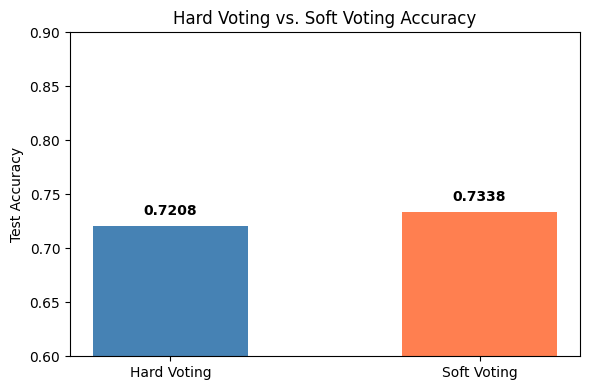

In [16]:
# Base Estimators
clf1 = LogisticRegression(random_state=42)
clf2 = SVC(probability=True, random_state=42)
clf3 = DecisionTreeClassifier(max_depth=3, random_state=42)

# Hard Voting Pipeline
hard_voting_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('voting', VotingClassifier(estimators=[('lr', clf1), ('svc', clf2), ('dt', clf3)], voting='hard'))
])

# Soft Voting Pipeline
soft_voting_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('voting', VotingClassifier(estimators=[('lr', clf1), ('svc', clf2), ('dt', clf3)], voting='soft'))
])

hard_voting_pipe.fit(X_train, y_train)
soft_voting_pipe.fit(X_train, y_train)

y_pred_hard = hard_voting_pipe.predict(X_test)
y_pred_soft = soft_voting_pipe.predict(X_test)

acc_hard = accuracy_score(y_test, y_pred_hard)
acc_soft = accuracy_score(y_test, y_pred_soft)

print(f"Hard Voting Accuracy: {acc_hard:.4f}")
print(f"Soft Voting Accuracy: {acc_soft:.4f}")

print("\n--- Hard Voting Classification Report ---")
print(classification_report(y_test, y_pred_hard))

print("\n--- Soft Voting Classification Report ---")
print(classification_report(y_test, y_pred_soft))

# Accuracy Plot
plt.figure(figsize=(6, 4))
plt.bar(['Hard Voting', 'Soft Voting'], [acc_hard, acc_soft], color=['steelblue', 'coral'], width=0.5)
plt.ylabel('Test Accuracy')
plt.ylim(0.6, 0.9)
plt.title('Hard Voting vs. Soft Voting Accuracy')
for i, v in enumerate([acc_hard, acc_soft]):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# Task 6: Bagging Classifier with Out-Of-Bag (OOB) Evaluation

### Overview & Operational Context
Bootstrap Aggregating (Bagging) reduces the high variance of unpruned decision trees by training an ensemble of trees on random bootstrap subsets (sampling with replacement). In any bootstrap draw of size $N$, roughly $36.8\%$ of samples are omitted. These unchosen instances serve as an internal validation set called the Out-of-Bag (OOB) sample, allowing validation during training without a dedicated split.

### Technical Implementation
1. We build a `BaggingClassifier` using `DecisionTreeClassifier()` base estimators with `bootstrap=True` and `oob_score=True` across 100 estimators.
2. We fit the pipeline, extract `oob_score_`, and compute the held-out test set accuracy.
3. We plot a side-by-side bar comparison of the OOB score versus test accuracy.

Out-of-Bag (OOB) Evaluation Score: 0.7557
Held-Out Test Set Accuracy:        0.7208


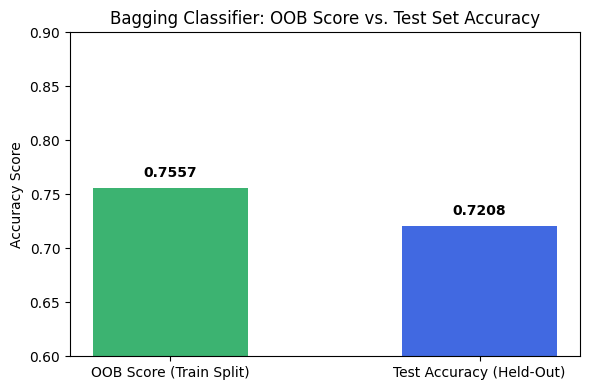

In [17]:
bagging_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('bagging', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_pipe.fit(X_train, y_train)

oob_score = bagging_pipe.named_steps['bagging'].oob_score_
test_acc_bag = accuracy_score(y_test, bagging_pipe.predict(X_test))

print(f"Out-of-Bag (OOB) Evaluation Score: {oob_score:.4f}")
print(f"Held-Out Test Set Accuracy:        {test_acc_bag:.4f}")

# Plot OOB vs Test Accuracy
plt.figure(figsize=(6, 4))
plt.bar(['OOB Score (Train Split)', 'Test Accuracy (Held-Out)'], [oob_score, test_acc_bag], color=['mediumseagreen', 'royalblue'], width=0.5)
plt.ylabel('Accuracy Score')
plt.ylim(0.6, 0.9)
plt.title('Bagging Classifier: OOB Score vs. Test Set Accuracy')
for i, v in enumerate([oob_score, test_acc_bag]):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# Task 7: Random Forest Classifier and Feature Importance Analysis

### Overview & Operational Context
Random Forests extend standard bagging by introducing random feature subsetting at every node split (typically selecting $\sqrt{p}$ features). This decorrelates individual trees, preventing dominant predictors (such as `glucose`) from appearing at every root node, thereby reducing overall ensemble variance.

### Technical Implementation
1. We instantiate a `RandomForestClassifier(n_estimators=100, random_state=42)` pipeline.
2. We evaluate its classification performance on the test set.
3. We extract Gini impurity feature importances (`feature_importances_`) and render a horizontal bar plot showing the relative contribution of each metabolic risk factor.

Random Forest Test Accuracy: 0.7727

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



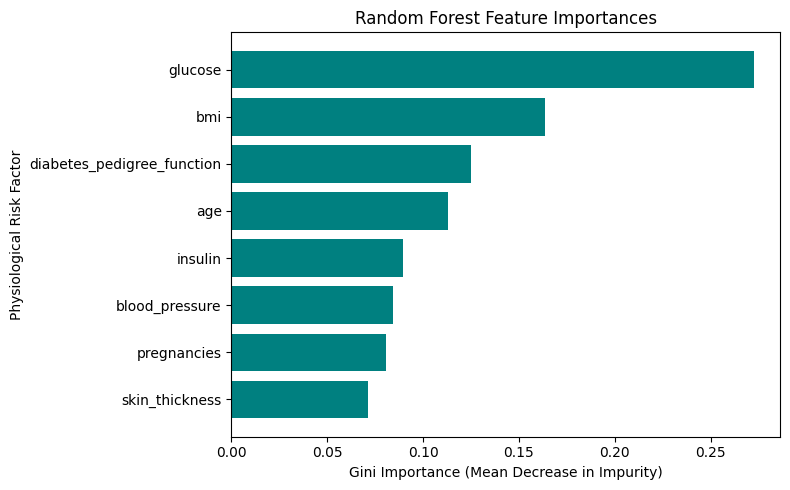

In [18]:
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Test Accuracy: {acc_rf:.4f}")
print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf))

# Extract feature importances
rf_model = rf_pipe.named_steps['rf']
importances = rf_model.feature_importances_
feat_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values(by='Importance', ascending=True)

# Horizontal Bar Plot
plt.figure(figsize=(8, 5))
plt.barh(feat_df['Feature'], feat_df['Importance'], color='teal')
plt.xlabel('Gini Importance (Mean Decrease in Impurity)')
plt.ylabel('Physiological Risk Factor')
plt.title('Random Forest Feature Importances')
plt.tight_layout()
plt.show()

# Task 8: AdaBoost Sequential Learning & Generalization Trends

### Overview & Operational Context
Unlike parallel ensemble methods, Adaptive Boosting (AdaBoost) trains estimators sequentially. Using shallow decision stumps (trees of `max_depth=1`), AdaBoost adaptively increases sample weights for instances misclassified in previous iterations, forcing subsequent learners to target underfitted regions of the feature space.

### Technical Implementation
1. We train an `AdaBoostClassifier` using decision stumps across estimator counts from 1 to 100.
2. At each iteration, we evaluate training accuracy versus test accuracy using staged predictions (`staged_predict`).
3. We plot learning curves of Training vs. Test Accuracy across boosting iterations to observe convergence and potential overfitting.

AdaBoost Final Train Accuracy: 0.7980
AdaBoost Final Test Accuracy:  0.7468


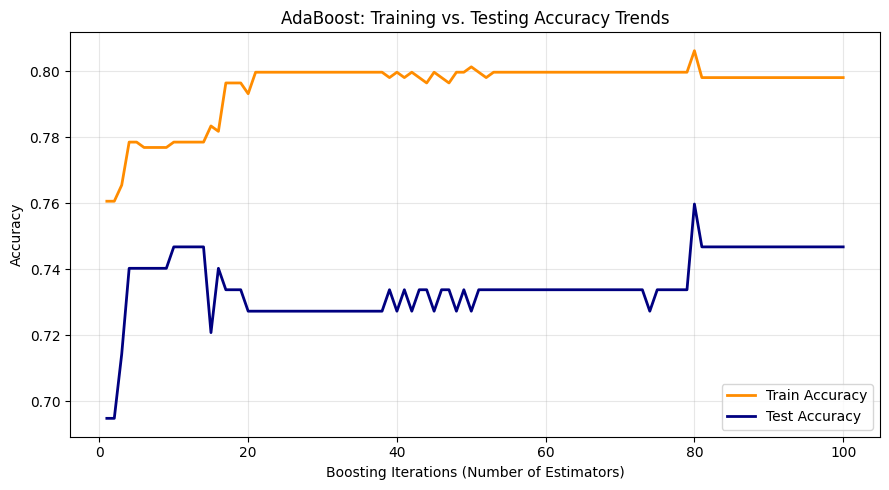

In [19]:
# Transform data once to iterate through staged predictions cleanly
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

adaboost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
adaboost.fit(X_train_trans, y_train)

# Evaluate staged predictions
train_scores = [accuracy_score(y_train, y_p) for y_p in adaboost.staged_predict(X_train_trans)]
test_scores = [accuracy_score(y_test, y_p) for y_p in adaboost.staged_predict(X_test_trans)]

print(f"AdaBoost Final Train Accuracy: {train_scores[-1]:.4f}")
print(f"AdaBoost Final Test Accuracy:  {test_scores[-1]:.4f}")

# Plot Generalization Trends
plt.figure(figsize=(9, 5))
plt.plot(range(1, 101), train_scores, label='Train Accuracy', color='darkorange', lw=2)
plt.plot(range(1, 101), test_scores, label='Test Accuracy', color='navy', lw=2)
plt.xlabel('Boosting Iterations (Number of Estimators)')
plt.ylabel('Accuracy')
plt.title('AdaBoost: Training vs. Testing Accuracy Trends')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()